# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib


# Data Loading

In [ ]:
df = pd.read_csv('tlast3.csv')
print(df.info())
print(df.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162567 entries, 0 to 162566
Data columns (total 11 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   date                    162285 non-null  object 
 1   source                  162285 non-null  object 
 2   destination             162285 non-null  object 
 3   distance_km             160635 non-null  float64
 4   congestion_index        160635 non-null  float64
 5   time_of_day             160430 non-null  object 
 6   weather                 160338 non-null  object 
 7   day_of_week             162285 non-null  object 
 8   festival                54757 non-null   object 
 9   actual_travel_time_min  160635 non-null  float64
 10  road_type               159424 non-null  object 
dtypes: float64(3), object(8)
memory usage: 13.6+ MB
None
         date    source              destination  distance_km  \
0  15-07-2022     Powai                   Airoli    14.256019   

# Data Preprocessing

In [3]:
print('Missing values:\n', df.isnull().sum())


Missing values:
 date                         282
source                       282
destination                  282
distance_km                 1932
congestion_index            1932
time_of_day                 2137
weather                     2229
day_of_week                  282
festival                  107810
actual_travel_time_min      1932
road_type                   3143
dtype: int64


# Feature Engineering

In [ ]:
# Drop festival column
df.drop(columns=['festival'], inplace=True)

# Fill missing numerical values with median
num_cols = ['distance_km', 'congestion_index', 'actual_travel_time_min']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
cat_cols = ['weather', 'road_type', 'time_of_day']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# --- Extract date features ---

df['date']        = pd.to_datetime(df['date'], errors='coerce')
df['day_of_week'] = df['date'].dt.day_name() 
df['month']       = df['date'].dt.month       

# --- Parse time of day ---
time_parsed       = pd.to_datetime(df['time_of_day'], format='%H:%M', errors='coerce')
df['time_in_hours'] = time_parsed.dt.hour + time_parsed.dt.minute / 60

# --- One-hot encode categoricals ---
# drop_first=True removes baseline: congested, Friday, Clear
df = pd.get_dummies(
    df,
    columns=['road_type', 'day_of_week', 'weather'],
    drop_first=True,
    dtype=int
)

df.dropna(inplace=True)

print('Columns after encoding:')
print(df.columns.tolist())


C:\Users\Ronish\AppData\Local\Temp\ipykernel_4428\2636935567.py:17: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['date']        = pd.to_datetime(df['date'], errors='coerce')


Columns after encoding:
['date', 'source', 'destination', 'distance_km', 'congestion_index', 'time_of_day', 'actual_travel_time_min', 'month', 'time_in_hours', 'road_type_freeway', 'road_type_urban', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday', 'weather_Cloudy', 'weather_Fog', 'weather_Heavy Rain', 'weather_Rain', 'weather_Storm']


# Outlier Detection & Removal

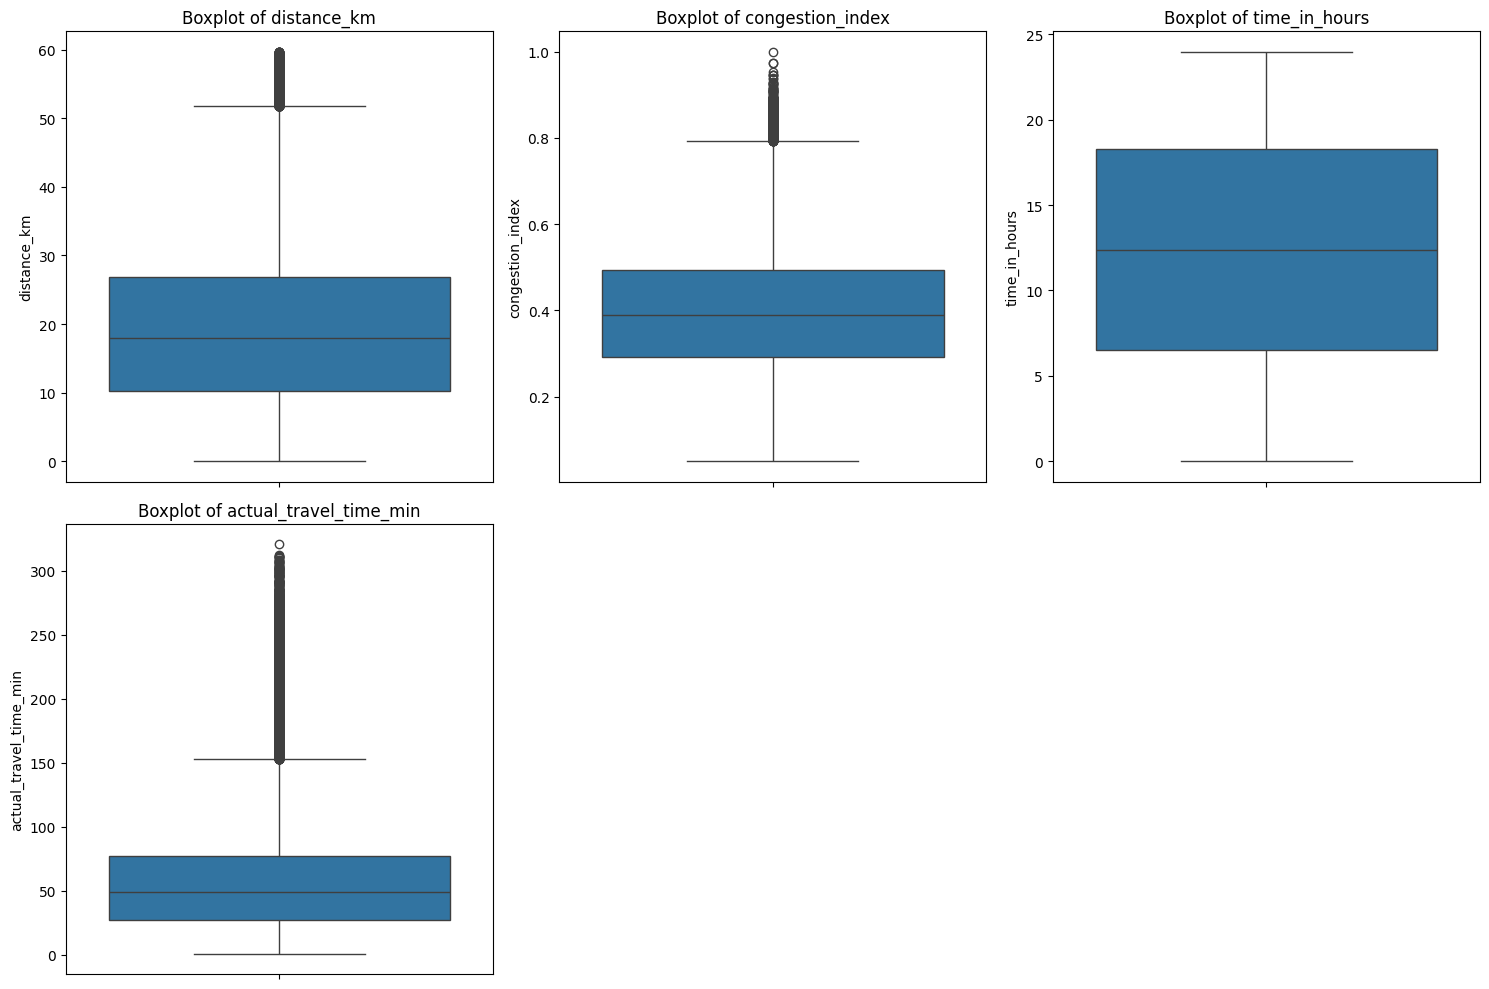

Shape after outlier removal: (156263, 22)


In [5]:
numerical_cols = ['distance_km', 'congestion_index', 'time_in_hours', 'actual_travel_time_min']

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.savefig('traffic-outliers.png')
plt.show()

Q1  = df[numerical_cols].quantile(0.25)
Q3  = df[numerical_cols].quantile(0.75)
IQR = Q3 - Q1
df  = df[~((df[numerical_cols] < (Q1 - 1.5 * IQR)) |
           (df[numerical_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

print('Shape after outlier removal:', df.shape)


# Train / Test Split

In [ ]:
X = df.drop(columns=[
    'actual_travel_time_min',  
    'date',                   
    'source',                  
    'destination',             
    'time_of_day',             
])
y = df['actual_travel_time_min']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Training shape:', X_train.shape)
print('Test shape:    ', X_test.shape)
print('\nFinal features used by model:')
for col in X.columns:
    print(' -', col)


Training shape: (125010, 17)
Test shape:     (31253, 17)

Final features used by model:
 - distance_km
 - congestion_index
 - month
 - time_in_hours
 - road_type_freeway
 - road_type_urban
 - day_of_week_Monday
 - day_of_week_Saturday
 - day_of_week_Sunday
 - day_of_week_Thursday
 - day_of_week_Tuesday
 - day_of_week_Wednesday
 - weather_Cloudy
 - weather_Fog
 - weather_Heavy Rain
 - weather_Rain
 - weather_Storm


Random Forest

In [ ]:
rf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators':     [100, 200, 300],
    'max_depth':        [None, 10, 20],
    'min_samples_leaf': [1, 3]
}

grid_search = GridSearchCV(rf, param_grid, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_search.fit(X_train, y_train)

model = grid_search.best_estimator_
model.fit(X_train, y_train)

print('Best params:', grid_search.best_params_)
print('Best CV RMSE:', -grid_search.best_score_)


Best params: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 300}
Best CV RMSE: 8.505102452123317


In [8]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
print(f'CV scores: {-cv_scores}')
print(f'CV RMSE:   {-cv_scores.mean():.2f}')


CV scores: [8.45037225 8.55739678 8.49572326 8.53072462 8.58358084]
CV RMSE:   8.52


# Model Evaluation

In [9]:
y_train_pred = model.predict(X_train)
y_test_pred  = model.predict(X_test)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse  = np.sqrt(mean_squared_error(y_test,  y_test_pred))
train_mae  = mean_absolute_error(y_train, y_train_pred)
test_mae   = mean_absolute_error(y_test,  y_test_pred)
train_r2   = r2_score(y_train, y_train_pred)
test_r2    = r2_score(y_test,  y_test_pred)

print('Random Forest Performance:')
print(f'  Train RMSE: {train_rmse:.2f}  |  Test RMSE: {test_rmse:.2f}')
print(f'  Train MAE:  {train_mae:.2f}  |  Test MAE:  {test_mae:.2f}')
print(f'  Train R²:   {train_r2:.4f}  |  Test R²:  {test_r2:.4f}')


Random Forest Performance:
  Train RMSE: 3.93  |  Test RMSE: 8.42
  Train MAE:  3.12  |  Test MAE:  6.59
  Train R²:   0.9864  |  Test R²:  0.9386


In [13]:
joblib.dump(model, '91.pkl')
print('Saved: traffic_congestion_model_v2.pkl')
print('Features the model expects:', model.feature_names_in_.tolist())


Saved: traffic_congestion_model_v2.pkl
Features the model expects: ['distance_km', 'congestion_index', 'month', 'time_in_hours', 'road_type_freeway', 'road_type_urban', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday', 'weather_Cloudy', 'weather_Fog', 'weather_Heavy Rain', 'weather_Rain', 'weather_Storm']


# Visualizations

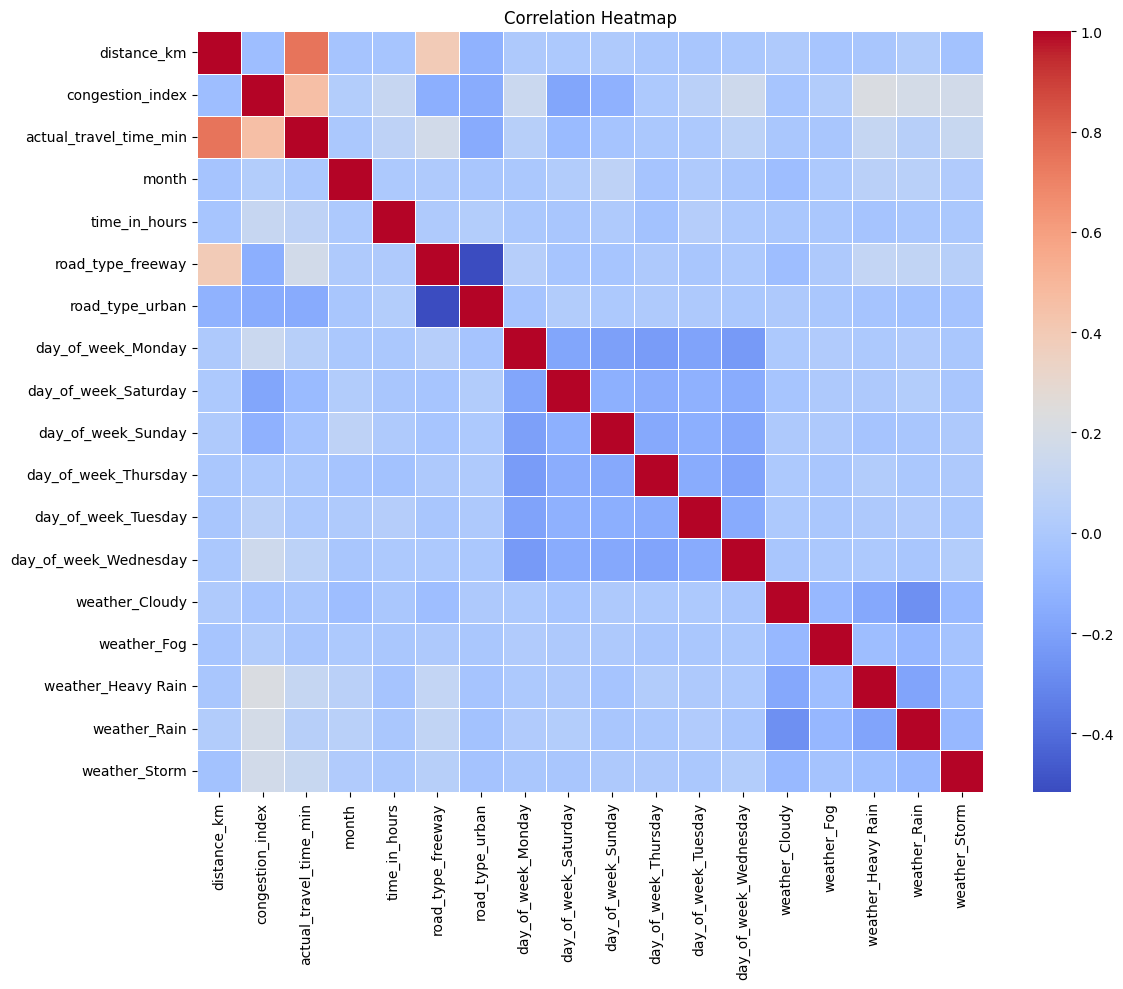

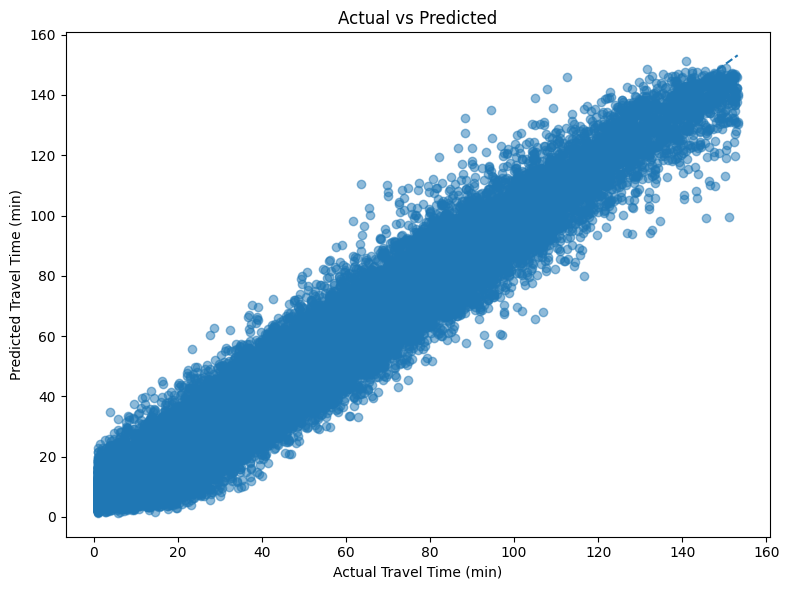

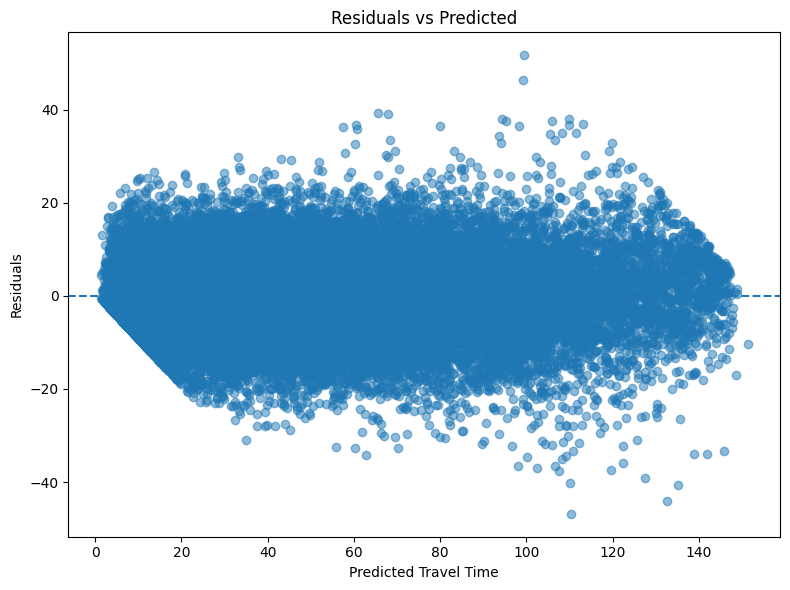

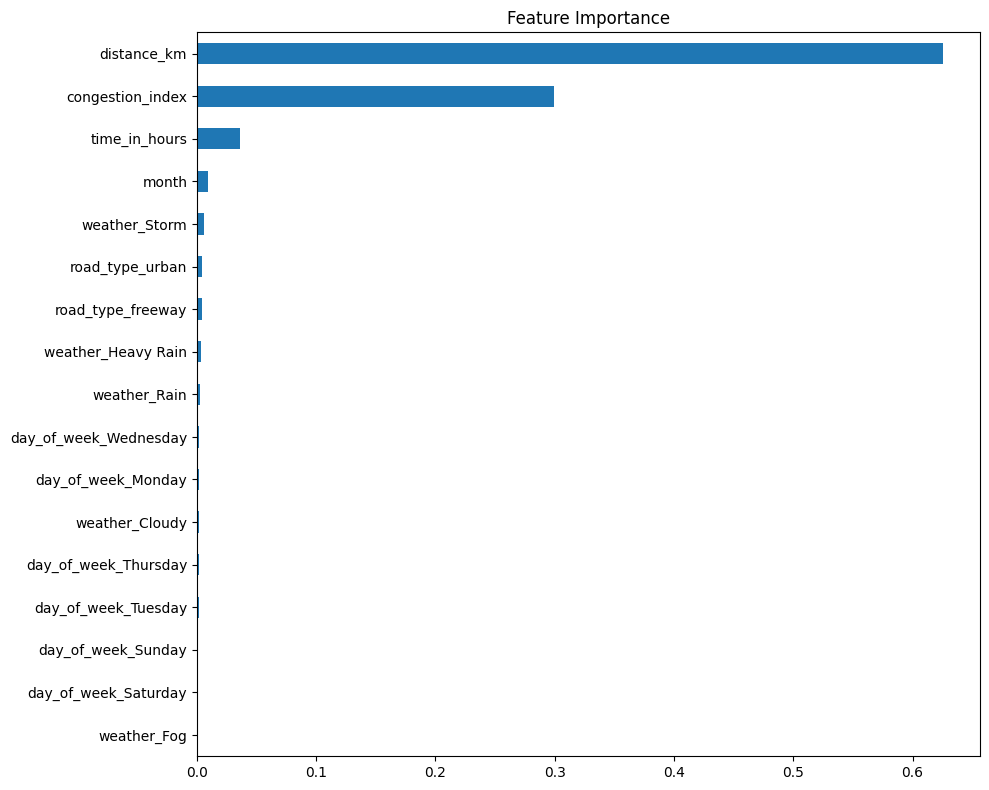

In [11]:
# Correlation Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('1_correlation_heatmap.png')
plt.show()

# Actual vs Predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle='--')
plt.xlabel('Actual Travel Time (min)')
plt.ylabel('Predicted Travel Time (min)')
plt.title('Actual vs Predicted')
plt.tight_layout()
plt.savefig('2_actual_vs_predicted.png')
plt.show()

# Residuals
plt.figure(figsize=(8, 6))
residuals = y_test - y_test_pred
plt.scatter(y_test_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle='--')
plt.xlabel('Predicted Travel Time')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.tight_layout()
plt.savefig('3_residual_plot.png')
plt.show()

# Feature Importance
plt.figure(figsize=(10, 8))
pd.Series(model.feature_importances_, index=X_train.columns).sort_values().plot(kind='barh')
plt.title('Feature Importance')
plt.tight_layout()
plt.savefig('4_feature_importance.png')
plt.show()


# Model Comparison

Linear Regression  — RMSE: 13.94 | MAE: 10.75 | R²: 0.8314
Gradient Boosting  — RMSE: 9.82 | MAE: 7.63 | R²: 0.9164
Random Forest      — RMSE: 8.42 | MAE: 6.59 | R²: 0.9386


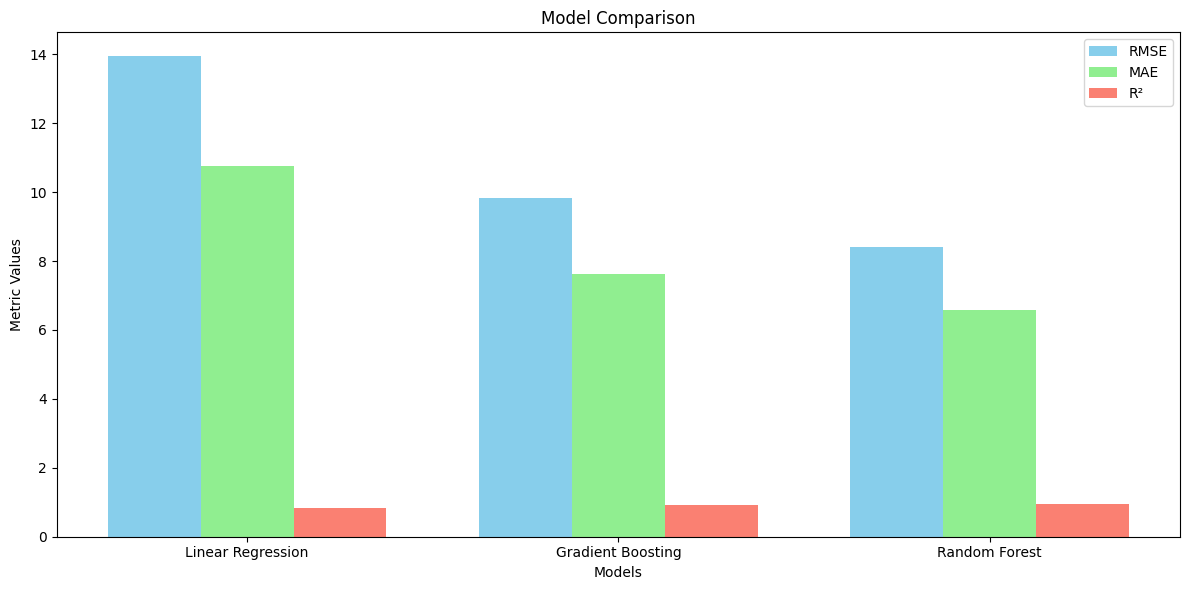

In [ ]:
# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
test_rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
test_mae_lr  = mean_absolute_error(y_test, y_pred_lr)
test_r2_lr   = r2_score(y_test, y_pred_lr)

# Gradient Boosting
gb = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    min_samples_leaf=3,
    min_samples_split=5,
    subsample=0.8,
    random_state=42
)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
test_rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
test_mae_gb  = mean_absolute_error(y_test, y_pred_gb)
test_r2_gb   = r2_score(y_test, y_pred_gb)

# Cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_lr_scores = -cross_val_score(
    lr, X_train, y_train,
    cv=kf,
    scoring='neg_root_mean_squared_error'
)

cv_gb_scores = -cross_val_score(
    gb, X_train, y_train,
    cv=kf,
    scoring='neg_root_mean_squared_error'
)

# Print results
print(f'Linear Regression  — RMSE: {test_rmse_lr:.2f} | MAE: {test_mae_lr:.2f} | R²: {test_r2_lr:.4f}')
print(f'Gradient Boosting  — RMSE: {test_rmse_gb:.2f} | MAE: {test_mae_gb:.2f} | R²: {test_r2_gb:.4f}')
print(f'Random Forest      — RMSE: {test_rmse:.2f} | MAE: {test_mae:.2f} | R²: {test_r2:.4f}')

# Visualization
x = np.arange(3)
bar_width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(x - bar_width, [test_rmse_lr, test_rmse_gb, test_rmse], width=bar_width, label='RMSE')
plt.bar(x,             [test_mae_lr,  test_mae_gb,  test_mae],  width=bar_width, label='MAE')
plt.bar(x + bar_width, [test_r2_lr,   test_r2_gb,   test_r2],   width=bar_width, label='R²')

plt.xticks(x, ['Linear Regression', 'Gradient Boosting', 'Random Forest'])
plt.xlabel('Models')
plt.ylabel('Metric Values')
plt.title('Model Comparison')

plt.legend()
plt.tight_layout()
plt.show()